# 13장 LLM 라벨링

루프의 4단계(오라클)에 Jev를 넣는다. 1~3부에서 라벨은 데이터셋의 정답이었다. 이 장에서는 Jev가 라벨을 붙인다. 라벨 스키마와 퓨샷 예시를 바꿔 가며 Jev 라벨의 정확도를 재고, 가장 나은 설정을 `oracle_fn` 시그니처의 Jev 오라클로 만들어 2장 루프에 끼운다.

- 13.1 Jev 오라클의 구조
- 13.2 라벨 스키마 정의
- 13.3 제로샷 라벨링 프롬프트
- 13.4 퓨샷 예시 선택 — 무작위·유사도·클래스 균형
- 13.5 오라클 함수 시그니처 호환 구현
- 13.6 라벨 정확도와 혼동 행렬

학생 모델은 1부와 같은 TF-IDF·로지스틱 회귀이고 CPU로 돈다. 질의 전략은 Random과 엔트로피로 고정해 오라클의 효과만 본다. 초기 라벨 100개는 사람(정답 라벨)이 붙이고, 퓨샷 예시도 이 100개에서 고른다. Jev 호출에 필요한 키·주소·모델 이름은 `jupyter/.env` 에서만 읽는다.

### 공통 코드

2장에서 정의한 데이터 읽기, 학생 모델, 시뮬레이션 오라클, 루프, 지표 함수를 그대로 다시 싣는다. 노트북마다 필요한 코드를 모두 담는 규칙을 따른다.

In [1]:
# ── 환경 설정과 상수 ────
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import koreanize_matplotlib
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, f1_score
from joblib import Parallel, delayed

SEEDS = [0, 1, 2, 3, 4]
N_INIT, K, BUDGET = 100, 50, 2000
ACCENT, INK, GRAY, GRAY2 = "#E32C24", "#1C1C1A", "#575753", "#8C8A85"
LABEL = {"acc": "정확도", "f1": "매크로 F1"}

# ── 데이터 읽기와 특징 추출 ────
def load_data(name):
    pool = pd.read_csv(f"data/{name}_pool.csv")
    test = pd.read_csv(f"data/{name}_test.csv")
    vec = TfidfVectorizer(analyzer="char_wb", ngram_range=(2, 4), min_df=2,
                          max_features=50000, sublinear_tf=True)
    X_pool = vec.fit_transform(pool.text)          # 라벨을 쓰지 않으므로 누수가 아니다
    return dict(name=name, texts=pool.text.values, X_pool=X_pool, y_pool=pool.label.values,
                X_test=vec.transform(test.text), y_test=test.label.values,
                n_classes=pool.label.nunique())

DATA = {name: load_data(name) for name in ("nsmc", "ynat")}
for d in DATA.values():
    print(d["name"], "풀", d["X_pool"].shape, "시험", d["X_test"].shape, "클래스", d["n_classes"])

# ── 학생 모델 ────
def train_model(X, y, seed):
    return LogisticRegression(C=10.0, max_iter=1000, random_state=seed).fit(X, y)

def proba(model, X, n_classes):
    # 라벨 집합에 없는 클래스의 확률 열을 0으로 채워 열 수를 고정한다
    P = np.zeros((X.shape[0], n_classes))
    P[:, model.classes_] = model.predict_proba(X)
    return P

# ── 시뮬레이션 오라클 ────
def make_sim_oracle(y_true):
    # 정답 라벨과 신뢰도 1.0을 돌려준다. 13장의 Jev 오라클이 같은 자리에 들어온다
    return lambda idx, texts: (y_true[idx], np.ones(len(idx)))

# ── 능동 학습 루프 ────
def run_loop(query_fn, oracle_fn, data, seed, n_init=N_INIT, k=K, budget=BUDGET):
    rng = np.random.default_rng(seed)
    n = data["X_pool"].shape[0]
    idx_l = rng.choice(n, n_init, replace=False)
    y_l, _ = oracle_fn(idx_l, data["texts"][idx_l])
    idx_u = np.setdiff1d(np.arange(n), idx_l)
    log = []
    while True:
        model = train_model(data["X_pool"][idx_l], y_l, seed)                          # 1. train
        y_hat = model.predict(data["X_test"])                                             # 평가
        log.append(dict(seed=seed, n_labeled=len(idx_l), acc=accuracy_score(data["y_test"], y_hat),
                        f1=f1_score(data["y_test"], y_hat, average="macro"), t_query=np.nan))
        if len(idx_l) >= budget:
            break
        t0 = time.perf_counter()
        q = query_fn(model, data, idx_l, y_l, idx_u, min(k, budget - len(idx_l)), rng)   # 2. predict · 3. query
        log[-1]["t_query"] = time.perf_counter() - t0
        y_q, _ = oracle_fn(q, data["texts"][q])                                           # 4. label
        idx_l, y_l = np.r_[idx_l, q], np.r_[y_l, y_q]                                     # 5. update
        idx_u = np.setdiff1d(idx_u, q)
    return pd.DataFrame(log), idx_l

# ── 무작위 질의 함수 ────
def query_random(model, data, idx_l, y_l, idx_u, k, rng):
    return rng.choice(idx_u, k, replace=False)

# ── 지표와 실험 도구 ────
def alc(n, m, budget=BUDGET):
    # 라벨 수를 [n0, budget] → [0, 1]로 정규화한 사다리꼴 적분. n0은 첫 측정점이다
    keep = n <= budget
    u, m = (n[keep] - n[0]) / (budget - n[0]), m[keep]
    return np.sum(np.diff(u) * (m[1:] + m[:-1]) / 2)

def label_efficiency(n, m, m_target, budget=BUDGET):
    hit = n[m >= m_target]
    return budget / hit[0] if len(hit) else np.nan

def run_strategies(strategies, data, seeds=SEEDS, n_jobs=-1, **kw):
    # (전략, 시드) 조합을 CPU 코어에 나눠 돌린다. 시드마다 난수 생성기가 따로라 순차 실행과 결과가 같다
    oracle = make_sim_oracle(data["y_pool"])
    jobs = [(name, s) for name in strategies for s in seeds]
    out = Parallel(n_jobs=n_jobs)(delayed(run_loop)(strategies[name], oracle, data, s, **kw) for name, s in jobs)
    print(f"{data['name']:5s} {', '.join(strategies)} 완료")
    return pd.concat([df.assign(strategy=name) for (name, _), (df, _) in zip(jobs, out)], ignore_index=True)

def summarize(res, metric="f1", ref="Random", budget=BUDGET):
    target = res[res.strategy == ref].groupby("n_labeled")[metric].mean().loc[budget]
    rows = []
    for name, g in res.groupby("strategy", sort=False):
        alcs = [alc(d.n_labeled.values, d[metric].values, budget) for _, d in g.groupby("seed")]
        curve = g.groupby("n_labeled")[metric].mean()
        rows.append(dict(strategy=name, ALC=np.mean(alcs), ALC_std=np.std(alcs), final=curve.loc[budget],
                         LE=label_efficiency(curve.index.values, curve.values, target, budget),
                         t_query=g[g.n_labeled < budget].t_query.mean()))
    return pd.DataFrame(rows).round(4)

STYLES = [(ACCENT, "-"), (INK, "--"), (GRAY, "-."), (GRAY2, ":"), ("#2B6CB0", "-"), ("#9C6B30", "--")]

def plot_curves(res, metric, ax, title):
    for (name, g), (c, ls) in zip(res.groupby("strategy", sort=False), STYLES):
        s = g.groupby("n_labeled")[metric].agg(["mean", "std"]).fillna(0)
        ax.plot(s.index, s["mean"], color=c, ls=ls, lw=1.6, label=name)
        ax.fill_between(s.index, s["mean"] - s["std"], s["mean"] + s["std"], color=c, alpha=0.12)
    ax.set(title=title, xlabel="라벨 수", ylabel=LABEL[metric])
    ax.grid(alpha=0.3)
    ax.legend(fontsize=8)

nsmc 풀 (20000, 50000) 시험 (10000, 50000) 클래스 2
ynat 풀 (20000, 50000) 시험 (9107, 50000) 클래스 7


질의 전략으로 쓸 3장의 엔트로피 점수를 다시 싣는다.

In [2]:
def score_entropy(P):
    return -(P * np.log(P + 1e-12)).sum(1)

def make_score_query(score_fn):
    def query_fn(model, data, idx_l, y_l, idx_u, k, rng):
        P = proba(model, data["X_pool"][idx_u], data["n_classes"])
        return idx_u[np.argsort(-score_fn(P))[:k]]
    return query_fn

query_entropy = make_score_query(score_entropy)

## 13.1 Jev 오라클의 구조

Jev 오라클은 2장의 `oracle_fn(idx, texts) -> (labels, conf)` 시그니처를 따른다. 질의된 문장을 50개씩 묶어 `state` 에 넣고, 문장마다 라벨을 묻는 choice 질문 `label_i` 를 붙인다. Jev는 선택지마다 확률을 돌려준다. 가장 큰 확률의 선택지를 라벨로, 그 확률을 신뢰도로 쓴다.

호출 함수 `jev_ask` 와 라벨 체계는 3부와 같다. 키·주소·모델 이름이 출력에 찍히지 않도록 환경변수는 설정 여부만 출력하고 오류 메시지도 가린다.

In [3]:
# ── Jev 호출 함수 ────
import os
import requests
from dotenv import load_dotenv
from concurrent.futures import ThreadPoolExecutor

load_dotenv(".env")                      # jupyter/.env — 키·주소·모델 이름은 여기에만 있다
print({n: bool(os.getenv(n)) for n in ("JEV_API_KEY", "JEV_BASE_URL", "JEV_MODEL")})   # 값은 출력하지 않는다

JEV = dict(key=os.environ["JEV_API_KEY"], url=os.environ["JEV_BASE_URL"].rstrip("/"), model=os.environ["JEV_MODEL"])
MAX_CONC = 5                             # 동시 호출 수
SESSION = requests.Session()

def mask(text):
    # 오류 메시지에 키·주소·모델 이름이 섞여 나오지 않도록 가린다
    for v in JEV.values():
        text = text.replace(v, "***")
    return text

def jev_ask(state, questions):
    # 판정 질문 묶음을 한 번 보내고 (질문 이름별 답, 입력 토큰, 출력 토큰)을 돌려준다
    body = dict(model=JEV["model"], state=state, questions=questions)
    for wait in (2, 4, 8, 16, 32, 64):                       # 일시 오류(429·5xx)는 잠시 쉬고 다시 보낸다
        r = SESSION.post(f"{JEV['url']}/v1/systemone", headers={"Authorization": f"Bearer {JEV['key']}"},
                         json=body, timeout=300)
        if r.status_code == 200:
            j = r.json()
            return j["answers"], j["usage"]["input_tokens"], j["usage"]["output_tokens"]
        time.sleep(wait)
    raise RuntimeError(mask(f"Jev 응답 {r.status_code}: {r.text[:300]}"))

{'JEV_API_KEY': True, 'JEV_BASE_URL': True, 'JEV_MODEL': True}


In [4]:
# ── 라벨 체계 ────
LABEL_NAMES = {"nsmc": ["부정", "긍정"],
               "ynat": ["IT과학", "경제", "사회", "생활문화", "세계", "스포츠", "정치"]}
LABEL_DESC = {"nsmc": {"부정": "영화를 부정적으로 평가한 리뷰", "긍정": "영화를 긍정적으로 평가한 리뷰"},
              "ynat": {"IT과학": "정보기술·과학 기사", "경제": "경제·산업·금융 기사", "사회": "사건·사고·사회 기사",
                       "생활문화": "생활·문화·건강·여행 기사", "세계": "국제·해외 기사", "스포츠": "스포츠 기사",
                       "정치": "정치·외교·북한 기사"}}
TASK = {"nsmc": "영화 리뷰의 감성", "ynat": "뉴스 기사 제목의 주제"}

In [5]:
# ── 검증 집합 ────
# 라벨 정확도·신뢰도는 루프와 떼어 검증 집합 2,000개에서 잰다. 시험 집합은 학생 모델 평가에만 쓴다
VAL = {name: pd.read_csv(f"data/{name}_val.csv") for name in DATA}
for name, v in VAL.items():
    print(name, "검증", len(v), "클래스별", np.bincount(v.label).tolist())

nsmc 검증 2000 클래스별 [1003, 997]
ynat 검증 2000 클래스별 [229, 268, 225, 252, 364, 339, 323]


## 13.2 라벨 스키마 정의

3부에서는 라벨 설명을 질문마다 선택지에 붙였다. 문장 50개면 같은 설명이 50번 들어가 요청의 90% 이상이 질문 정의였다. 4부는 라벨 스키마를 `state` 맨 위에 한 번만 적고 질문의 선택지에는 라벨 이름만 둔다(슬림 형식).

스키마는 세 단계로 나눈다.

| 스키마 | state에 적는 것 |
|---|---|
| S0 | 라벨 이름 목록 |
| S1 | 라벨마다 한 줄 설명 |
| S2 | S1 + 헷갈리는 경우의 경계 규칙 |

경계 규칙은 데이터셋의 라벨 정의와 일반 상식으로만 썼다. 검증 집합의 오답을 보고 규칙을 고치지 않는다. 그렇게 고친 규칙은 검증 집합에 맞춰진 것이라 정확도가 실제보다 높게 나온다.

In [6]:
# ── 라벨 스키마와 요청 만들기 ────
CHUNK = 50                               # 요청 하나에 넣는 문장 수
TASK_SENT = {"nsmc": "영화 리뷰의 감성을 분류한다.", "ynat": "뉴스 기사 제목의 주제를 분류한다."}
RULES = {"nsmc": ["반어나 비꼼으로 칭찬하는 척하는 리뷰는 부정이다",
                  "칭찬과 불만이 섞이면 글쓴이의 최종 평가를 따른다",
                  "영화 밖의 이야기(배우, 다른 관객)라도 영화에 대한 태도가 드러나면 그 태도를 따른다"],
         "ynat": ["기업·산업·시장·금융·부동산은 경제다. IT 제품·통신·인터넷 서비스·과학 연구는 IT과학이다",
                  "사건·사고·교육·노동·법원·지역 소식은 사회다",
                  "국내 정치·국회·정당·외교·북한은 정치다. 외국 정부와 해외에서 일어난 일은 세계다",
                  "문화·연예·건강·여행·종교·생활 정보는 생활문화다",
                  "경기 결과·선수·구단·대회는 스포츠다"]}

def schema_text(name, level):
    # level 0: 라벨 이름만, 1: 라벨 설명, 2: 설명 + 경계 규칙
    lines = [f"과제: {TASK_SENT[name]}", "라벨:"]
    lines += [f"- {n}: {LABEL_DESC[name][n]}" if level >= 1 else f"- {n}" for n in LABEL_NAMES[name]]
    lines += ["경계 규칙:"] + [f"- {r}" for r in RULES[name]] if level == 2 else []
    return "\n".join(lines)

def build_request(name, texts, schema=1, rich=False, shots=(), near=None):
    # state = 스키마 → 퓨샷 예시 → 분류할 문장. 질문은 문장마다 label_i 하나
    one = lambda t: str(t).replace("\n", " ")
    parts = [] if schema is None else [schema_text(name, schema)]
    parts += ["예시:\n" + "\n".join(f'- "{one(t)}" → {y}' for t, y in shots)] if len(shots) else []
    items = [f"[{i}] {one(t)}" + ("" if near is None else "\n    비슷한 예시: " + "; ".join(f'"{one(a)}" → {b}' for a, b in near[i]))
             for i, t in enumerate(texts)]
    state = "\n\n".join(parts + ["분류할 문장:\n" + "\n".join(items)])
    crit = LABEL_DESC[name] if rich else {n: None for n in LABEL_NAMES[name]}
    ask = f"{TASK[name]}은?" if rich else "라벨"
    qs = {f"label_{i}": {"type": "choice", "instructions": f"[{i}]번 문장의 {ask}", "criteria": crit} for i in range(len(texts))}
    return state, qs

In [7]:
# ── 요청 예시 ────
v = VAL["ynat"]
state, qs = build_request("ynat", v.text.values[:3], schema=2)
print(state)
print(qs["label_0"])
st3, qs3 = build_request("ynat", v.text.values[:3], schema=None, rich=True)
print("\n3부 형식 질문:", qs3["label_0"])

import json

# 문장 50개 요청 하나에서 문장·스키마(state)와 질문 정의(questions)의 글자 수
for name in DATA:
    texts = VAL[name].text.values[:CHUNK]
    for key, cfg in (("슬림 S2", dict(schema=2)), ("3부 형식", dict(schema=None, rich=True))):
        st, q = build_request(name, texts, **cfg)
        n_q = len(json.dumps(q, ensure_ascii=False))
        print(f"{name} {key}: state {len(st):,}자 | questions {n_q:,}자 | 질문 비중 {n_q / (len(st) + n_q):.0%}")

과제: 뉴스 기사 제목의 주제를 분류한다.
라벨:
- IT과학: 정보기술·과학 기사
- 경제: 경제·산업·금융 기사
- 사회: 사건·사고·사회 기사
- 생활문화: 생활·문화·건강·여행 기사
- 세계: 국제·해외 기사
- 스포츠: 스포츠 기사
- 정치: 정치·외교·북한 기사
경계 규칙:
- 기업·산업·시장·금융·부동산은 경제다. IT 제품·통신·인터넷 서비스·과학 연구는 IT과학이다
- 사건·사고·교육·노동·법원·지역 소식은 사회다
- 국내 정치·국회·정당·외교·북한은 정치다. 외국 정부와 해외에서 일어난 일은 세계다
- 문화·연예·건강·여행·종교·생활 정보는 생활문화다
- 경기 결과·선수·구단·대회는 스포츠다

분류할 문장:
[0] 여자농구 삼성생명 OK저축은행에 완승…연패 탈출
[1] 김종민 도로공사 감독 더는 체력 이야기 안 한다
[2] 국정원 러시아 월드컵 안전정보 담은 핸드북 배포
{'type': 'choice', 'instructions': '[0]번 문장의 라벨', 'criteria': {'IT과학': None, '경제': None, '사회': None, '생활문화': None, '세계': None, '스포츠': None, '정치': None}}

3부 형식 질문: {'type': 'choice', 'instructions': '[0]번 문장의 뉴스 기사 제목의 주제은?', 'criteria': {'IT과학': '정보기술·과학 기사', '경제': '경제·산업·금융 기사', '사회': '사건·사고·사회 기사', '생활문화': '생활·문화·건강·여행 기사', '세계': '국제·해외 기사', '스포츠': '스포츠 기사', '정치': '정치·외교·북한 기사'}}
nsmc 슬림 S2: state 2,522자 | questions 5,080자 | 질문 비중 67%
nsmc 3부 형식: state 2,333자 | questions 6,930자 | 질문 비중 75%
ynat 슬림 S2: state 1,932자 | questions 8,330자 | 질문 비중 81%

## 13.3 제로샷 라벨링 프롬프트

예시 없이 스키마만 주고 라벨을 받는다. `jev_label` 이 문장을 50개씩 묶어 동시에 5개까지 보내고, 선택지 확률 행렬과 답의 confidence, 묶음별 토큰을 돌려준다.

먼저 검증 집합 앞 50개로 슬림 형식과 3부 형식을 한 번씩 보내 본다. 문장당 입력 토큰과 정답률, 그리고 답의 confidence가 최대 선택지 확률과 같은 값인지 확인한다.

In [8]:
# ── Jev 라벨 판정 ────
def jev_label(name, texts, cfg, near=None):
    # texts를 50개씩 묶어 판정한다. (선택지 확률 행렬, 답의 confidence, 묶음별 사용량)을 돌려준다
    names = LABEL_NAMES[name]
    def one(s):
        state, qs = build_request(name, texts[s:s + CHUNK], near=None if near is None else near[s:s + CHUNK], **cfg)
        t0 = time.perf_counter()
        ans, a, b = jev_ask(state, qs)
        P = [[ans[f"label_{i}"]["probabilities"].get(n, 0.0) for n in names] for i in range(len(qs))]
        c = [ans[f"label_{i}"]["confidence"] for i in range(len(qs))]
        return P, c, dict(n_in=a, n_out=b, t=time.perf_counter() - t0, n=len(qs))
    with ThreadPoolExecutor(MAX_CONC) as ex:
        out = list(ex.map(one, range(0, len(texts), CHUNK)))
    P = np.array([p for o in out for p in o[0]])
    return P / P.sum(1, keepdims=True), np.array([c for o in out for c in o[1]]), pd.DataFrame([o[2] for o in out])

In [9]:
# ── 첫 호출 점검 ────
for name in DATA:
    v = VAL[name]
    texts, y = v.text.values[:CHUNK], v.label.values[:CHUNK]
    for key, cfg in (("슬림 S1", dict(schema=1)), ("3부 형식", dict(schema=None, rich=True))):
        P, c, u = jev_label(name, texts, cfg)
        print(f"{name} {key}: 입력 {u.n_in.sum():,}토큰(문장당 {u.n_in.sum() / len(texts):.1f}) | 출력 {u.n_out.sum():,} | "
              f"{u.t.sum():.1f}초 | 정답률 {(P.argmax(1) == y).mean():.2f} | confidence − 최대 확률 최대 차이 {np.abs(c - P.max(1)).max():.3f}")

nsmc 슬림 S1: 입력 3,909토큰(문장당 78.2) | 출력 1,762 | 0.2초 | 정답률 0.88 | confidence − 최대 확률 최대 차이 0.490


nsmc 3부 형식: 입력 6,205토큰(문장당 124.1) | 출력 1,762 | 0.2초 | 정답률 0.88 | confidence − 최대 확률 최대 차이 0.490


ynat 슬림 S1: 입력 5,189토큰(문장당 103.8) | 출력 3,753 | 0.2초 | 정답률 0.82 | confidence − 최대 확률 최대 차이 0.110


ynat 3부 형식: 입력 10,233토큰(문장당 204.7) | 출력 3,751 | 0.2초 | 정답률 0.82 | confidence − 최대 확률 최대 차이 0.090


검증 집합 2,000개 전체로 네 형식(S0, S1, S2, 3부 형식)을 비교한다. 결과는 형식마다 `results/ch13_parts/` 에 저장해 다시 돌릴 때 Jev를 부르지 않는다.

In [10]:
# ── 정적 평가 ────
os.makedirs("results/ch13_parts", exist_ok=True)

def static_eval(name, key, cfg, near=None):
    path = f"results/ch13_parts/static_{name}_{key}.csv"
    if os.path.exists(path):
        return pd.read_csv(path)
    v = VAL[name]
    P, c, u = jev_label(name, v.text.values, cfg, near)
    df = pd.DataFrame(P, columns=[f"p{j}" for j in range(P.shape[1])]).assign(y=v.label.values, conf=c)
    df["n_in"] = np.repeat(u.n_in.values / u.n.values, u.n.values)            # 묶음의 입력 토큰을 문장 수로 나눠 싣는다
    df["t"] = np.repeat(u.t.values / u.n.values, u.n.values)
    df.to_csv(path, index=False)
    return df

def label_metrics(df):
    P = df.filter(regex=r"^p\d").values
    yh = P.argmax(1)
    return dict(acc=accuracy_score(df.y, yh), f1=f1_score(df.y, yh, average="macro"),
                conf=P.max(1).mean(), tok=df.n_in.mean())

SCHEMAS = {"S0": dict(schema=0), "S1": dict(schema=1), "S2": dict(schema=2), "3부 형식": dict(schema=None, rich=True)}
static = {name: {k: static_eval(name, k, cfg) for k, cfg in SCHEMAS.items()} for name in DATA}
tab_schema = {name: pd.DataFrame({k: label_metrics(df) for k, df in s.items()}).T.round(4) for name, s in static.items()}
for name, t in tab_schema.items():
    print(f"\n{name} 스키마별 Jev 라벨 (검증 2,000, tok = 문장당 입력 토큰)")
    print(t.to_string())
BEST_SCHEMA = {name: t.drop("3부 형식").f1.idxmax() for name, t in tab_schema.items()}
print("\n퓨샷 실험에 쓸 슬림 스키마:", BEST_SCHEMA)


nsmc 스키마별 Jev 라벨 (검증 2,000, tok = 문장당 입력 토큰)
          acc      f1    conf      tok
S0     0.8895  0.8895  0.9340   74.533
S1     0.8930  0.8930  0.9331   75.073
S2     0.8920  0.8920  0.9227   76.893
3부 형식  0.8900  0.8900  0.9397  120.993

ynat 스키마별 Jev 라벨 (검증 2,000, tok = 문장당 입력 토큰)
         acc      f1    conf       tok
S0     0.810  0.7886  0.8732  103.8235
S1     0.820  0.7926  0.8917  105.0035
S2     0.825  0.8067  0.8882  108.0635
3부 형식  0.805  0.7832  0.8700  205.8835

퓨샷 실험에 쓸 슬림 스키마: {'nsmc': 'S1', 'ynat': 'S2'}


## 13.4 퓨샷 예시 선택 — 무작위·유사도·클래스 균형

13.3절에서 가장 나은 슬림 스키마에 예시를 더한다. 예시는 초기 라벨 100개(사람 라벨)에서만 고른다. 실제 현장에서도 쓸 수 있는 예시는 이미 라벨을 붙인 데이터뿐이다.

| 선택 | 방법 | 예시 수 |
|---|---|---|
| 무작위 | 100개에서 무작위 | NSMC 4·8, YNAT 7·14 |
| 클래스 균형 | 클래스마다 같은 수를 무작위 | 같음 |
| 유사도 | 문장마다 TF-IDF 코사인이 가장 가까운 예시 2개를 그 문장 아래에 붙인다 | 문장당 2 |

무작위·균형 예시는 요청마다 같은 묶음을 `state` 에 한 번 적는다. 유사도 예시는 문장마다 달라 토큰이 더 든다. 예시는 시드 0의 초기 라벨 100개에서 고른다. 토큰을 아끼려고 예시 묶음은 한 벌만 돌린다(저자 결정). 그래서 예시 묶음이 바뀔 때의 흔들림은 이 표에 없다.

In [11]:
# ── 퓨샷 예시 ────
VEC = {name: TfidfVectorizer(analyzer="char_wb", ngram_range=(2, 4), min_df=2, max_features=50000, sublinear_tf=True)
            .fit(pd.read_csv(f"data/{name}_pool.csv").text) for name in DATA}       # load_data와 같은 설정
X_VAL = {name: VEC[name].transform(VAL[name].text) for name in DATA}

def init_idx(d, seed):
    # run_loop가 시드 seed에서 뽑는 초기 라벨 100개와 같다
    return np.random.default_rng(seed).choice(d["X_pool"].shape[0], N_INIT, replace=False)

def shots_of(d, idx):
    return [(d["texts"][i], LABEL_NAMES[d["name"]][d["y_pool"][i]]) for i in idx]

def pick_rand(d, idx0, n, rng):
    return rng.choice(idx0, n, replace=False)

def pick_bal(d, idx0, n, rng):
    y0 = d["y_pool"][idx0]
    pick = np.concatenate([rng.choice(idx0[y0 == c], n // d["n_classes"], replace=False) for c in range(d["n_classes"])])
    return rng.permutation(pick)

def near_shots(d, idx0, Xq, m=2):
    # 문장마다 초기 라벨 가운데 코사인이 가장 큰 예시 m개
    S = (Xq @ d["X_pool"][idx0].T).toarray()
    return [shots_of(d, idx0[np.argsort(-s)[:m]]) for s in S]

N_SHOTS = {"nsmc": (4, 8), "ynat": (7, 14)}
print("시드 0 균형 예시(YNAT 7):")
for t, y in shots_of(DATA["ynat"], pick_bal(DATA["ynat"], init_idx(DATA["ynat"], 0), 7, np.random.default_rng(0))):
    print(f"  {y:5s} | {t}")

시드 0 균형 예시(YNAT 7):
  세계    | 美러 중거리핵전력조약 위반 논쟁 핵심 쟁점은
  스포츠   | V리그 최초 9천 디그 김해란 리베로의 숙명 견뎌야...
  경제    | 원달러 환율 소폭 상승…금융시장 불확실성 여전
  사회    | 위기의 MBN 평일 오후 보도 프로그램 강화
  IT과학  | 그래픽 인터넷뱅킹 이용률 3년새 45%→58% 증가
  생활문화  | 경기도 8개 시·군 오후 4시 건조주의보…가평 한파경보
  정치    | 이인영 내일 조국 인사청문회해야…안되면 국민과 직접 만날것종합


In [12]:
# ── 퓨샷 정적 평가 ────
FS_SEEDS = [0]
fs_rows = []
for name, d in DATA.items():
    base = dict(schema=int(BEST_SCHEMA[name][1]))
    for s in FS_SEEDS:
        idx0 = init_idx(d, s)
        runs = {f"{m}{n}": dict(base, shots=shots_of(d, f(d, idx0, n, np.random.default_rng(s))))   # 13.5절 오라클과 같은 예시
                for m, f in (("무작위", pick_rand), ("균형", pick_bal)) for n in N_SHOTS[name]}
        for key, cfg in runs.items():
            fs_rows.append(dict(data=name, setting=key, seed=s, **label_metrics(static_eval(name, f"{key}_s{s}", cfg))))
        df = static_eval(name, f"유사도2_s{s}", base, near=near_shots(d, idx0, X_VAL[name]))
        fs_rows.append(dict(data=name, setting="유사도2", seed=s, **label_metrics(df)))
fs = pd.DataFrame(fs_rows)

zero = pd.DataFrame([dict(data=n, setting=f"제로샷 {BEST_SCHEMA[n]}", seed=0, **tab_schema[n].loc[BEST_SCHEMA[n]].to_dict()) for n in DATA])
tab_fs = (pd.concat([zero, fs]).groupby(["data", "setting"], sort=False)
          .agg(acc=("acc", "mean"), f1=("f1", "mean"), f1_min=("f1", "min"), f1_max=("f1", "max"), conf=("conf", "mean"), tok=("tok", "mean")).round(4))
print(tab_fs.to_string())
BEST_FS = {n: tab_fs.loc[n].f1.idxmax() for n in DATA}
print("\n루프에 쓸 설정:", BEST_FS)

                 acc      f1  f1_min  f1_max    conf       tok
data setting                                                  
nsmc 제로샷 S1   0.8930  0.8930  0.8930  0.8930  0.9331   75.0730
ynat 제로샷 S2   0.8250  0.8067  0.8067  0.8067  0.8882  108.0635
nsmc 무작위4     0.8910  0.8910  0.8910  0.8910  0.9321   78.8930
     무작위8     0.8935  0.8935  0.8935  0.8935  0.9314   81.2130
     균형4      0.8955  0.8955  0.8955  0.8955  0.9321   77.1130
     균형8      0.8980  0.8980  0.8980  0.8980  0.9317   81.6930
     유사도2     0.8875  0.8875  0.8875  0.8875  0.9230  162.2435
ynat 무작위7     0.8270  0.8094  0.8094  0.8094  0.8821  111.9435
     무작위14    0.8400  0.8217  0.8217  0.8217  0.8879  116.1835
     균형7      0.8415  0.8229  0.8229  0.8229  0.8924  112.2035
     균형14     0.8320  0.8126  0.8126  0.8126  0.8858  115.8035
     유사도2     0.8265  0.8113  0.8113  0.8113  0.8856  170.9210

루프에 쓸 설정: {'nsmc': '균형8', 'ynat': '균형7'}


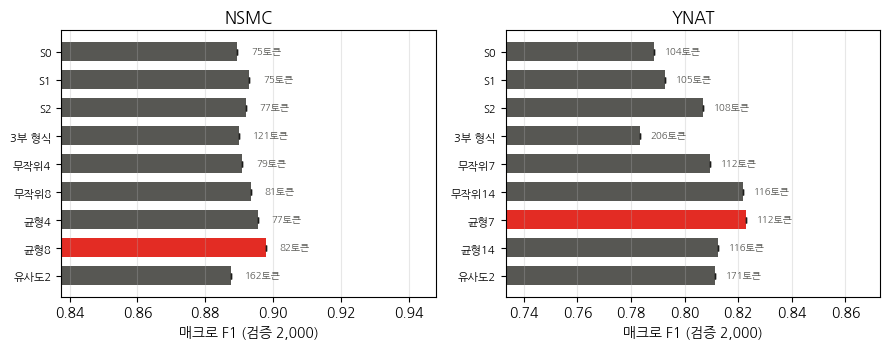

In [13]:
# ── 스키마·퓨샷 그림 ────
fig, axes = plt.subplots(1, 2, figsize=(9, 3.6))
for ax, name in zip(axes, DATA):
    t = pd.concat([tab_schema[name][["f1", "tok"]].assign(f1_min=lambda x: x.f1, f1_max=lambda x: x.f1),
                   tab_fs.loc[name].iloc[1:][["f1", "f1_min", "f1_max", "tok"]]])
    colors = [ACCENT if k == BEST_FS[name] or (BEST_FS[name].startswith("제로샷") and k == BEST_SCHEMA[name]) else GRAY for k in t.index]
    y = np.arange(len(t))[::-1]
    ax.barh(y, t.f1, color=colors, height=0.65)
    ax.errorbar(t.f1, y, xerr=[t.f1 - t.f1_min, t.f1_max - t.f1], fmt="none", ecolor=INK, lw=0.9, capsize=2)
    for yi, (f, tok) in zip(y, zip(t.f1, t.tok)):
        ax.text(f + 0.004, yi, f"{tok:.0f}토큰", va="center", fontsize=7, color=GRAY)
    ax.set(yticks=y, yticklabels=t.index, title=name.upper(), xlabel="매크로 F1 (검증 2,000)",
           xlim=(t.f1_min.min() - 0.05, min(1.0, t.f1_max.max() + 0.05)))
    ax.tick_params(axis="y", labelsize=8)
    ax.grid(alpha=0.3, axis="x")
fig.tight_layout()
fig.savefig("out/ch13_schema_fewshot.png", dpi=200)

## 13.5 오라클 함수 시그니처 호환 구현

`make_jev_oracle` 이 2장 시그니처의 오라클을 만든다. 루프의 첫 호출(초기 라벨 100개)은 사람이 붙인다. 그 뒤로 질의된 문장은 13.4절에서 고른 설정으로 Jev가 붙인다. 퓨샷 예시는 그 실행의 초기 라벨 100개에서 고르므로 시드마다 다르다. 오라클은 라운드마다 토큰, 호출 시간, 붙인 라벨의 정답률을 자기 속성 `log` 에 쌓는다.

학생 모델은 Jev 라벨로 학습하고, 평가는 지금까지처럼 시험 집합의 정답 라벨로 한다.

In [14]:
# ── Jev 오라클 ────
def fs_config(d, key, idx0, texts, seed):
    # 13.4절 설정 이름(예: 균형14, 유사도2, 제로샷 S2)을 요청 설정과 문장별 예시로 바꾼다
    cfg, rng = dict(schema=int(BEST_SCHEMA[d["name"]][1])), np.random.default_rng(seed)
    pickers = {"무작위": pick_rand, "균형": pick_bal}
    m = next((p for p in pickers if key.startswith(p)), None)
    shots = shots_of(d, pickers[m](d, idx0, int(key[len(m):]), rng)) if m else ()
    near = near_shots(d, idx0, VEC[d["name"]].transform(texts)) if key.startswith("유사도") else None
    return dict(cfg, shots=shots), near

def make_jev_oracle(d, key, seed):
    log, mem = [], {}
    def oracle_fn(idx, texts):
        if "idx0" not in mem:                                    # 첫 호출: 초기 라벨은 사람이 붙인다
            mem["idx0"] = idx
            return d["y_pool"][idx], np.ones(len(idx))
        cfg, near = fs_config(d, key, mem["idx0"], texts, seed)
        P, c, u = jev_label(d["name"], texts, cfg, near)
        y = P.argmax(1)
        log.append(dict(n_in=u.n_in.sum(), n_out=u.n_out.sum(), calls=len(u), t_jev=u.t.sum(),
                        jev_acc=(y == d["y_pool"][idx]).mean(), jev_conf=P.max(1).mean()))
        return y, P.max(1)
    oracle_fn.log = log
    return oracle_fn

In [15]:
# ── 루프 실험 ────
QUERY = {"Random": query_random, "엔트로피": query_entropy}

def run_jev_loop(name, qname, d, seed):
    path = f"results/ch13_parts/loop_{name}_{qname}_{seed}.csv"
    if os.path.exists(path):
        return pd.read_csv(path)
    oracle = make_jev_oracle(d, BEST_FS[name], seed)
    df, _ = run_loop(QUERY[qname], oracle, d, seed)
    df = pd.concat([df, pd.DataFrame(oracle.log)], axis=1).assign(strategy=f"{qname}·Jev")
    df.to_csv(path, index=False)
    return df

loop = {}
for name, d in DATA.items():
    human = run_strategies(QUERY, d).replace({"strategy": {"Random": "Random·사람", "엔트로피": "엔트로피·사람"}})
    ch03 = pd.read_csv(f"results/ch03_{name}.csv")
    for q in QUERY:
        diff = np.abs(ch03[ch03.strategy == q].f1.values - human[human.strategy == f"{q}·사람"].f1.values).max()
        print(name, q, "3장 대비 F1 최대 차이:", diff)
    t0 = time.perf_counter()
    with ThreadPoolExecutor(MAX_CONC) as ex:
        jev = list(ex.map(lambda a: run_jev_loop(name, a[0], d, a[1]), [(q, s) for q in QUERY for s in SEEDS]))
    print(f"{name} Jev 오라클 루프 완료 {(time.perf_counter() - t0) / 60:.1f}분")
    loop[name] = pd.concat([human, *jev], ignore_index=True)

nsmc  Random, 엔트로피 완료
nsmc Random 3장 대비 F1 최대 차이: 5.551115123125783e-17
nsmc 엔트로피 3장 대비 F1 최대 차이: 5.551115123125783e-17


nsmc Jev 오라클 루프 완료 0.4분


ynat  Random, 엔트로피 완료
ynat Random 3장 대비 F1 최대 차이: 8.326672684688674e-17
ynat 엔트로피 3장 대비 F1 최대 차이: 8.326672684688674e-17


ynat Jev 오라클 루프 완료 3.8분



nsmc 매크로 F1 (라벨 100~2,000, LE 기준: Random·사람의 라벨 2,000 성능)
               ALC  ALC_std   final      LE  t_query  jev_acc  jev_conf       n_in   t_jev  n_in_run
strategy                                                                                            
Random·사람   0.7426   0.0034  0.7802  1.0000   0.0001      NaN       NaN        NaN     NaN       NaN
Random·Jev  0.7453   0.0040  0.7798     NaN   0.0000   0.8988    0.9290  4086.4526  0.2058  155285.2
엔트로피·사람     0.7479   0.0055  0.7860  1.2121   0.0110      NaN       NaN        NaN     NaN       NaN
엔트로피·Jev    0.7469   0.0079  0.7858  1.1765   0.0059   0.8573    0.8995  4060.3316  0.2071  154292.6

ynat 매크로 F1 (라벨 100~2,000, LE 기준: Random·사람의 라벨 2,000 성능)
               ALC  ALC_std   final      LE  t_query  jev_acc  jev_conf       n_in   t_jev  n_in_run
strategy                                                                                            
Random·사람   0.5335   0.0068  0.6500  1.0000   0.0001      NaN       NaN   

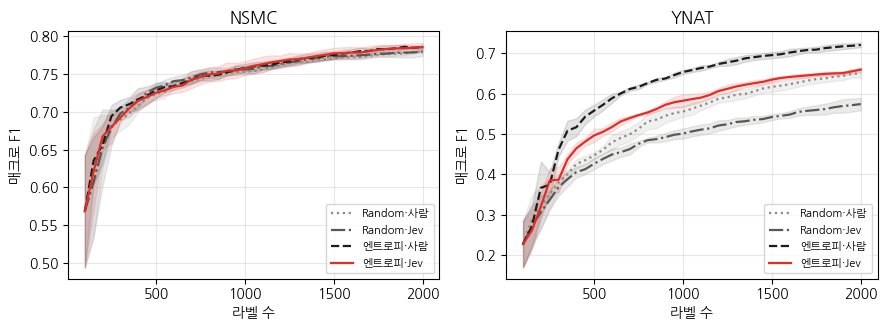

In [16]:
# ── 학습 곡선과 지표 ────
ORDER = ["Random·사람", "Random·Jev", "엔트로피·사람", "엔트로피·Jev"]
STYLES = [(GRAY2, ":"), (GRAY, "-."), (INK, "--"), (ACCENT, "-")]
for name, r in loop.items():
    r = r.set_index("strategy").loc[ORDER].reset_index()
    loop[name] = r
    t = summarize(r, "f1", ref="Random·사람").set_index("strategy")
    u = r[r.n_in.notna()].groupby("strategy", sort=False).agg(jev_acc=("jev_acc", "mean"), jev_conf=("jev_conf", "mean"),
                                                             n_in=("n_in", "mean"), t_jev=("t_jev", "mean"),
                                                             n_in_run=("n_in", lambda x: x.sum() / len(SEEDS)))
    print(f"\n{name} 매크로 F1 (라벨 100~2,000, LE 기준: Random·사람의 라벨 2,000 성능)")
    print(t.join(u).round(4).to_string())

fig, axes = plt.subplots(1, 2, figsize=(9, 3.4))
for ax, (name, r) in zip(axes, loop.items()):
    plot_curves(r, "f1", ax, name.upper())
fig.tight_layout()
fig.savefig("out/ch13_curve.png", dpi=200)

Jev 라벨의 정답률이 라운드에 따라 어떻게 바뀌는지 본다. 엔트로피는 학생이 헷갈리는 문장을 고르므로 Random보다 Jev에게도 어려운 문장이 몰릴 수 있다. 라운드별 정답률과 학습 집합 전체의 누적 노이즈율(초기 100개는 정답으로 센다)을 함께 출력한다.

In [17]:
# ── 라운드별 Jev 라벨 정답률 ────
for name, r in loop.items():
    g = r[r.n_in.notna()].copy()
    g["round"] = (g.n_labeled - N_INIT) // K
    g["noise_cum"] = g.groupby(["strategy", "seed"]).apply(
        lambda x: (K * (1 - x.jev_acc)).cumsum() / (x.n_labeled + K), include_groups=False).reset_index(level=[0, 1], drop=True)
    t = g.groupby(["strategy", "round"]).agg(acc=("jev_acc", "mean"), noise=("noise_cum", "mean")).unstack(0)
    print(f"\n{name} 라운드별 Jev 라벨 정답률과 누적 노이즈율")
    print(t.iloc[[0, 5, 10, 20, 30, 37]].round(4).to_string())


nsmc 라운드별 Jev 라벨 정답률과 누적 노이즈율
                acc               noise         
strategy Random·Jev 엔트로피·Jev Random·Jev 엔트로피·Jev
round                                           
0             0.916    0.892     0.0280   0.0360
5             0.912    0.820     0.0755   0.1065
10            0.880    0.848     0.0837   0.1172
20            0.860    0.868     0.0920   0.1273
30            0.896    0.856     0.0922   0.1345
37            0.888    0.868     0.0961   0.1356

ynat 라운드별 Jev 라벨 정답률과 누적 노이즈율
                acc               noise         
strategy Random·Jev 엔트로피·Jev Random·Jev 엔트로피·Jev
round                                           
0             0.832    0.684     0.0560   0.1053
5             0.836    0.784     0.1285   0.1675
10            0.808    0.768     0.1415   0.2018
20            0.772    0.720     0.1557   0.2383
30            0.868    0.696     0.1575   0.2524
37            0.836    0.720     0.1615   0.2607


## 13.6 라벨 정확도와 혼동 행렬

루프에 쓴 설정의 검증 집합 결과(시드 0 예시)로 혼동 행렬을 그린다. 행은 정답 라벨, 열은 Jev 라벨이고 행마다 합이 1이 되게 나눴다. 어떤 클래스 쌍에서 오류가 몰리는지 보고, 가장 많이 헷갈린 쌍의 사례를 싣는다.

정답 라벨이 늘 맞는 것은 아니다. 12장 감사에서 「엄청재밌는영화입니다」가 부정으로 라벨링된 사례를 봤다. Jev가 높은 신뢰도로 정답 라벨과 다르게 답한 사례도 따로 싣는다. 여기서는 어느 쪽이 맞는지 판단하지 않고 「정답 라벨과 다르다」고만 적는다.


nsmc 클래스별 재현율: {'부정': 0.893, '긍정': 0.903}
nsmc 가장 많이 헷갈린 쌍
 정답 Jev    비율
부정  긍정 0.107
긍정  부정 0.097

ynat 클래스별 재현율: {'IT과학': 0.921, '경제': 0.836, '사회': 0.453, '생활문화': 0.929, '세계': 0.772, '스포츠': 0.982, '정치': 0.923}
ynat 가장 많이 헷갈린 쌍
 정답  Jev    비율
사회   정치 0.164
사회   경제 0.129
경제 IT과학 0.119
사회 생활문화 0.102


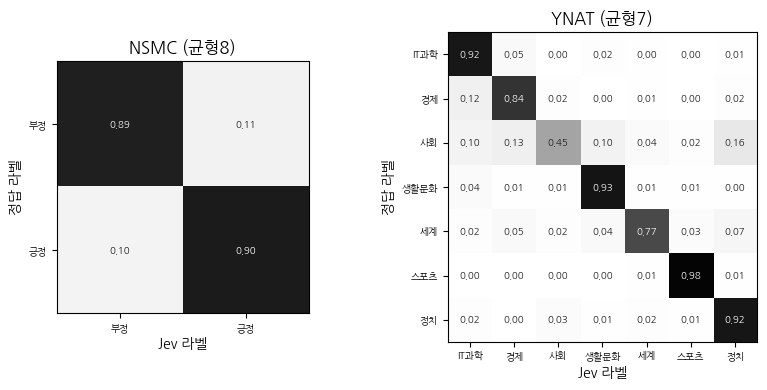

In [18]:
# ── 혼동 행렬 ────
from sklearn.metrics import confusion_matrix

def best_static(name):
    key = BEST_FS[name]
    return static[name][BEST_SCHEMA[name]] if key.startswith("제로샷") else pd.read_csv(f"results/ch13_parts/static_{name}_{key}_s0.csv")

fig, axes = plt.subplots(1, 2, figsize=(9, 4.0), gridspec_kw=dict(width_ratios=[1, 2.2]))
for ax, name in zip(axes, DATA):
    df, names = best_static(name), LABEL_NAMES[name]
    yh = df.filter(regex=r"^p\d").values.argmax(1)
    cm = confusion_matrix(df.y, yh, normalize="true")
    ax.imshow(cm, cmap="Greys", vmin=0, vmax=1)
    for i in range(len(names)):
        for j in range(len(names)):
            ax.text(j, i, f"{cm[i, j]:.2f}", ha="center", va="center", fontsize=7, color="white" if cm[i, j] > 0.5 else INK)
    ax.set(xticks=range(len(names)), yticks=range(len(names)), xticklabels=names, yticklabels=names,
           title=f"{name.upper()} ({BEST_FS[name]})", xlabel="Jev 라벨", ylabel="정답 라벨")
    ax.tick_params(labelsize=7)
    print(f"\n{name} 클래스별 재현율:", dict(zip(names, cm.diagonal().round(3))))
    off = pd.DataFrame([(names[i], names[j], cm[i, j]) for i in range(len(names)) for j in range(len(names)) if i != j],
                       columns=["정답", "Jev", "비율"]).nlargest(4, "비율")
    print(f"{name} 가장 많이 헷갈린 쌍\n", off.round(3).to_string(index=False))
fig.tight_layout()
fig.savefig("out/ch13_confusion.png", dpi=200)

In [19]:
# ── 오류 사례 ────
for name in DATA:
    df, names, texts = best_static(name), LABEL_NAMES[name], VAL[name].text.values
    P = df.filter(regex=r"^p\d").values
    e = df.assign(jev=P.argmax(1), c=P.max(1), text=texts)
    e = e[e.jev != e.y]
    print(f"\n{name}: 정답 라벨과 다른 Jev 라벨 {len(e)}개 ({len(e) / len(df):.1%}), 그중 신뢰도 0.9 이상 {(e.c >= 0.9).sum()}개")
    top = e.groupby(["y", "jev"]).size().idxmax()
    print(f"  가장 많은 쌍 정답 {names[top[0]]} → Jev {names[top[1]]}:")
    for _, x in e[(e.y == top[0]) & (e.jev == top[1])].head(3).iterrows():
        print(f"    {x.c:.2f} | {str(x.text)[:45]}")
    print("  신뢰도가 가장 높은 불일치:")
    for _, x in e.nlargest(4, "c").iterrows():
        print(f"    {x.c:.2f} | 정답 {names[int(x.y)]} Jev {names[int(x.jev)]} | {str(x.text)[:45]}")


nsmc: 정답 라벨과 다른 Jev 라벨 204개 (10.2%), 그중 신뢰도 0.9 이상 80개
  가장 많은 쌍 정답 부정 → Jev 긍정:
    0.51 | 남극은 왔는데 그만 길을 잃었다. 오르지 못할 곳은 오르는 것이 아니다.
    0.88 | 핫세는 정말 이뿌더랑~
    0.88 | 영화관 가서 보기엔 본전생각이 날듯..
  신뢰도가 가장 높은 불일치:
    1.00 | 정답 긍정 Jev 부정 | 사람들이 흔히말하는 '10점도 부족하다'라는 말은 진짜다
    1.00 | 정답 부정 Jev 긍정 | 아트오브워 3와 대적해도 꿀리지 않을 영화
    1.00 | 정답 긍정 Jev 부정 | 아아..1시간30분동안 나는 지옥을 보앗도다.
    1.00 | 정답 부정 Jev 긍정 | 트렁크씬의 연기는 정말 압권

ynat: 정답 라벨과 다른 Jev 라벨 317개 (15.8%), 그중 신뢰도 0.9 이상 76개
  가장 많은 쌍 정답 사회 → Jev 정치:
    0.50 | 국정원 러시아 월드컵 안전정보 담은 핸드북 배포
    0.87 | 법제처장 대통령 뜻 헤아려 법률 심사 결론 내리지 않아
    0.54 | 이효성 방통위원장 분리공시제로 통신비 부담 줄이겠다종합
  신뢰도가 가장 높은 불일치:
    1.00 | 정답 세계 Jev 스포츠 | 웨인 루니 맨시티가 역대 최강 2008년 맨유가 더 강했다
    1.00 | 정답 세계 Jev 스포츠 | 휴스턴 매의 눈에 교란 작전으로 응수한 스트라스버그
    1.00 | 정답 세계 Jev 스포츠 | 웨인 루니 맨유 첫 250골 대기록…후반 45분 극장 골
    1.00 | 정답 사회 Jev 경제 | 거래단속·중도금 대출규제에 강남 재건축시장 숨고르기


In [20]:
# ── 이 장이 쓴 Jev 입력 토큰 ────
import glob
files = [f for f in glob.glob("results/ch13_parts/*.csv") if not f.endswith(("_picks.csv", "_log.csv"))]
total = sum(pd.read_csv(f).filter(regex="^n_in").sum().sum() for f in files)
print(f"결과 파일에 기록된 Jev 입력 토큰 합: {total:,.0f}")

결과 파일에 기록된 Jev 입력 토큰 합: 7,630,451
